In [ ]:
# Mount Google Drive to access your files
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive/Kagglecatsanddogs
!ls -a


/content/drive/MyDrive/Kagglecatsanddogs
64x3-CNN.keras	catlookingdog.webp  Dog		 DTest2.jpg    sarah.jpg
aarshia.jpg	catshark.jpg	    dogg.webp	 DTest.jpeg    sirmog.avif
bandana.avif	CatTest.jpg	    Doggy.jpg	 ishvica.webp  X.pickle
Cat		CTest2.jpg	    dog.jpg	 logs	       y.pickle
cat.jpg		CTest.jpg	    DogTest.jpg  monkey.jpg


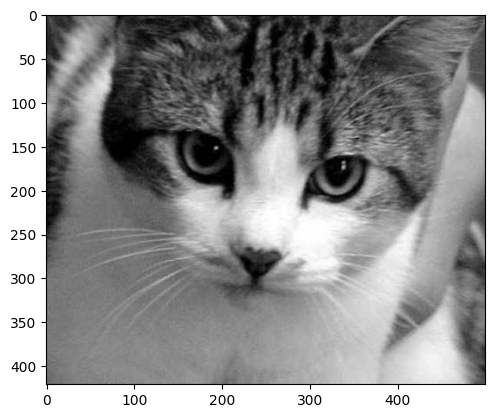

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

!pip install opencv-python

# Update DATADIR to reflect the path in your Google Drive
# Make sure to upload your 'kagglecatsanddogs_5340' folder to your Google Drive
DATADIR = "/content/drive/My Drive/Kagglecatsanddogs"
CATEGORIES = ["Cat", "Dog"]

for category in CATEGORIES:
  path = os.path.join(DATADIR, category) #path to cats or dogs

  for img in os.listdir(path):
    img_array = cv2.imread(os.path.join(path,img), cv2.IMREAD_GRAYSCALE)
    plt.imshow(img_array, cmap='gray')
    plt.show()
    break
  break









In [ ]:
print(img_array.shape)

(421, 500)


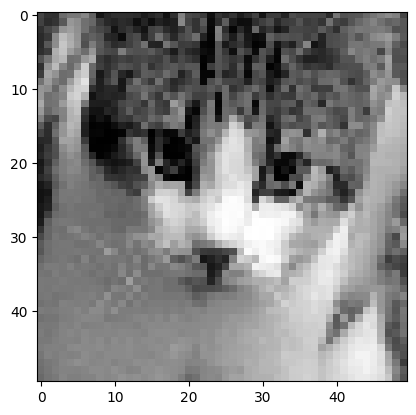

In [ ]:
IMG_SIZE = 50

new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
plt.imshow(new_array, cmap = 'gray')
plt.show()

In [ ]:
training_data = []
def create_training_data():
  for category in CATEGORIES:
      path = os.path.join(DATADIR, category) #path to cats or dogs
      class_num = CATEGORIES.index(category)
      # Add a counter for the images in the current category
      image_count = 0
      for img in os.listdir(path):
          if image_count >= 100: # Limit to 300 images per category
              break
          try:
              img_array = cv2.imread(os.path.join(path,img), cv2.IMREAD_GRAYSCALE)
              new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
              training_data.append([new_array, class_num])
              image_count += 1
          except Exception as e:
              pass

create_training_data()

In [ ]:
num_images = 0
for category in CATEGORIES:
    path = os.path.join(DATADIR, category)
    count = len(os.listdir(path))
    num_images += count
    print(f"Category '{category}' has {count} images.")

print(f"\nTotal images to process: {num_images}")

Category 'Cat' has 12500 images.
Category 'Dog' has 12500 images.

Total images to process: 25000


In [ ]:
print(len(training_data))

200


In [ ]:
import random

random.shuffle(training_data)

In [ ]:
for sample in training_data[:10]:
  print(sample[1])

1
1
1
1
0
0
0
0
0
1


In [ ]:
X = []
y = []

In [ ]:
for features, label in training_data:
    X.append(features)
    y.append(label)

X = np.array(X).reshape(-1, IMG_SIZE, IMG_SIZE, 1)

In [ ]:
import pickle

pickle_out = open("X.pickle", "wb")
pickle.dump(X, pickle_out)
pickle_out.close()

pickle_out = open("y.pickle", "wb")
pickle.dump(y, pickle_out)
pickle_out.close()

In [ ]:
pickle_in = open("X.pickle", "rb")
X = pickle.load(pickle_in)

In [ ]:
X[3]

array([[[ 67],
        [ 83],
        [ 71],
        ...,
        [125],
        [121],
        [121]],

       [[ 76],
        [ 88],
        [ 76],
        ...,
        [133],
        [121],
        [132]],

       [[ 75],
        [ 81],
        [ 82],
        ...,
        [118],
        [130],
        [141]],

       ...,

       [[181],
        [175],
        [128],
        ...,
        [105],
        [108],
        [154]],

       [[104],
        [176],
        [154],
        ...,
        [119],
        [149],
        [135]],

       [[121],
        [ 71],
        [ 91],
        ...,
        [111],
        [127],
        [123]]], dtype=uint8)

**3RD & 4TH VIDEO**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.callbacks import TensorBoard #for 4th video in series
import pickle
import numpy as np
import time #makes model totally unique so you dont end up overwritting model or appending model

NAME = "Cats-vs.dog-cnn-64x2-{}".format(int(time.time())) #two dense layers with 64 neurons each

tensorboard = TensorBoard(log_dir='logs/{}'.format(NAME)) #tells Keras exactly where to store the logging data and logs/{}places log files into a folder called logs and puts them inside a specific sub-folder named after the NAME variable generated

X = pickle.load(open("X.pickle", "rb"))
y = pickle.load(open("y.pickle", "rb"))

y = np.array(y) # Convert y to a NumPy array
X = X/255.0 # image data only goes form 0 to 255

model = Sequential()
model.add(Conv2D(64, (3,3), input_shape = X.shape[1:]))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size= (2,2)))

model.add(Conv2D(64, (3,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size= (2,2)))


model.add(Flatten())
model.add(Dense(64))


model.add(Dense(1))
model.add(Activation('sigmoid'))  #output layer


model.compile(loss="binary_crossentropy",
              optimizer = "adam",
              metrics=['accuracy'])

model.fit(X, y, batch_size=32, epochs=10, validation_split=0.2, callbacks = [tensorboard])
model.save('64x3-CNN.keras') # Changed filename to include .keras extension

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 316ms/step - accuracy: 0.4625 - loss: 0.7691 - val_accuracy: 0.5500 - val_loss: 0.6925
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6313 - loss: 0.6794 - val_accuracy: 0.3750 - val_loss: 0.6973
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.6062 - loss: 0.6744 - val_accuracy: 0.4500 - val_loss: 0.6971
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7000 - loss: 0.6529 - val_accuracy: 0.7000 - val_loss: 0.6690
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8313 - loss: 0.6173 - val_accuracy: 0.5250 - val_loss: 0.6757
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8125 - loss: 0.5660 - val_accuracy: 0.5000 - val_loss: 0.6838
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7875 - loss: 0.5144 - val_accuracy: 0.5750 - val_loss: 0.6653
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7812 - loss: 0.4739 - val_accuracy: 0.4250 - val_loss: 0.9923

**HAVE TO DO 5TH & RE-DO 4TH VIDEO**

Code for 5th video

**6TH VIDEO**

In [ ]:
import cv2
import tensorflow as tf
import os # Import os for path manipulation

CATEGORIES = ["Cat", "Dog"]
# Assuming DATADIR is defined in a previous cell and accessible, if not, redefine here
DATADIR = "/content/drive/My Drive/Kagglecatsanddogs"

def prepare(filepath):
    IMG_SIZE = 50
    img_array = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
    return new_array.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

model = tf.keras.models.load_model("64x3-CNN.keras")

# Construct the full path to the test image
#test_image_path = os.path.join(DATADIR, 'CatTest.jpg')
#input_data = prepare(test_image_path)




In [ ]:
prediction = model.predict([prepare('cat.jpg')])
print( CATEGORIES[int(prediction[0][0])])

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=('Tensor(shape=(1, 50, 50, 1))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step
Cat


In [ ]:
prediction = model.predict([prepare('dog.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Dog


In [ ]:
prediction = model.predict([prepare('CatTest.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Dog


In [ ]:
prediction = model.predict([prepare('DogTest.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Dog


In [ ]:
prediction = model.predict([prepare('CTest.jpg')])
print( CATEGORIES[int(prediction[0][0])]) # incorrect!!!!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Dog


In [ ]:
prediction = model.predict([prepare('DTest.jpeg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Dog


In [ ]:
prediction = model.predict([prepare('CTest2.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Cat


In [ ]:
prediction = model.predict([prepare('Doggy.jpg')])
print( CATEGORIES[int(prediction[0][0])]) #incorrect!!!!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Dog


In [ ]:
prediction = model.predict([prepare('dogg.webp')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Dog


In [ ]:
prediction = model.predict([prepare('catlookingdog.webp')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Dog


In [ ]:
prediction = model.predict([prepare('catshark.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Dog


In [ ]:
prediction = model.predict([prepare('sarah.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Dog


In [ ]:
prediction = model.predict([prepare('aarshia.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Dog


In [ ]:
prediction = model.predict([prepare('ishvica.webp')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Cat


In [ ]:
prediction = model.predict([prepare('sirmog.avif')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Cat


In [ ]:
prediction = model.predict([prepare('bandana.avif')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Dog


In [ ]:
prediction = model.predict([prepare('monkey.jpg')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step
Dog


In [ ]:
prediction = model.predict([prepare('ridhima.webp')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Dog


In [ ]:
prediction = model.predict([prepare('humancat.webp')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Dog


In [ ]:
prediction = model.predict([prepare('catdog.webp')])
print( CATEGORIES[int(prediction[0][0])])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Dog


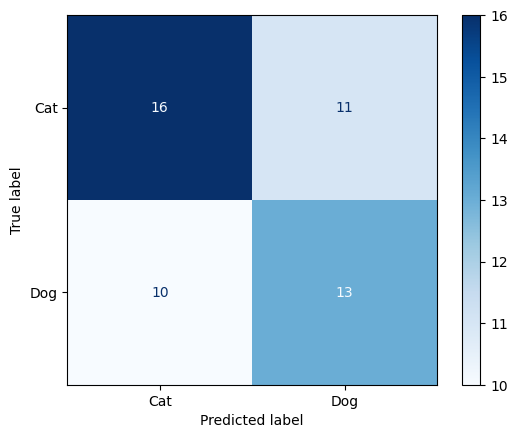

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

y_true = np.random.randint(0, 2, size=50) # Example true labels (0 or 1)
y_pred = np.random.randint(0, 2, size=50) # Example predicted labels (0 or 1)

cm = confusion_matrix(y_true=y_true, y_pred=y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Cat', 'Dog'])
disp.plot(cmap=plt.cm.Blues)
plt.show()